# EXERCÍCIOS - CÁLCULO NUMÉRICO

## 1) Isolamento de Raízes

**a)** f(x) = x^3 - 4x - 1

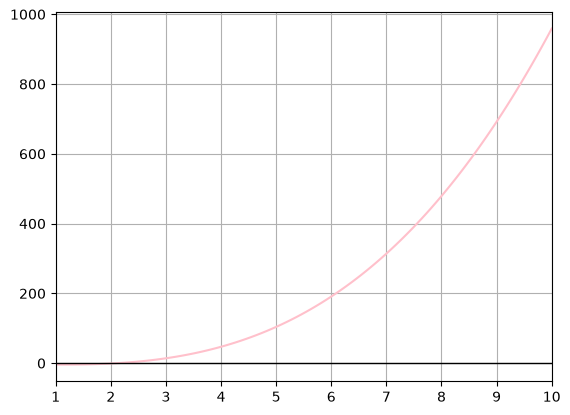

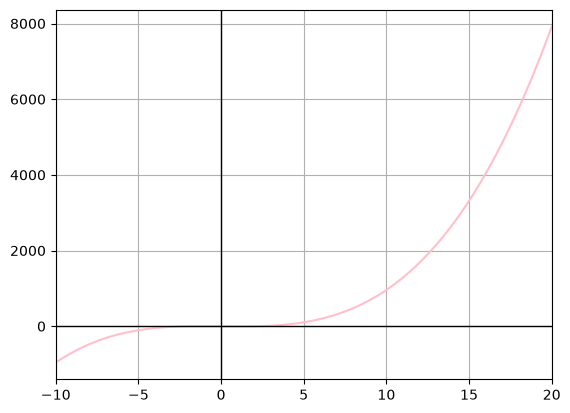

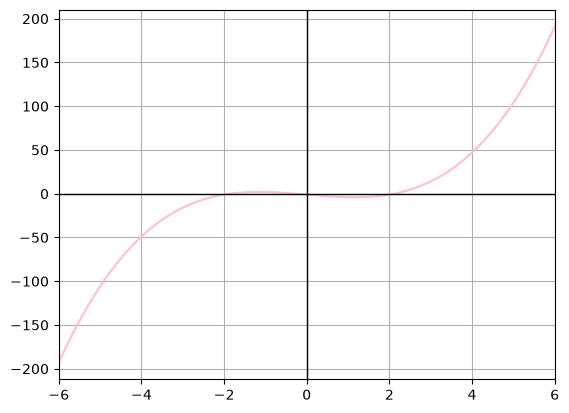

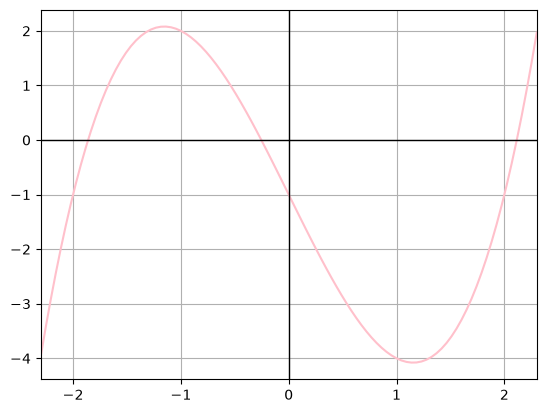

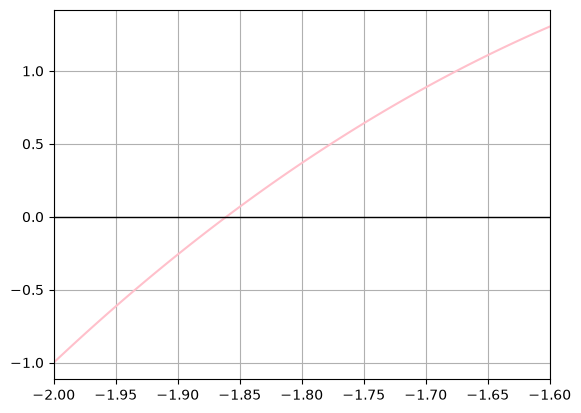

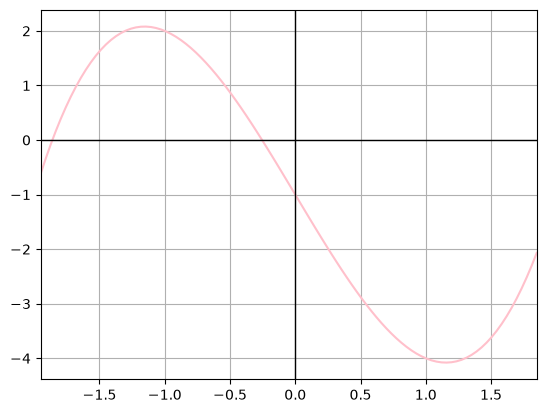

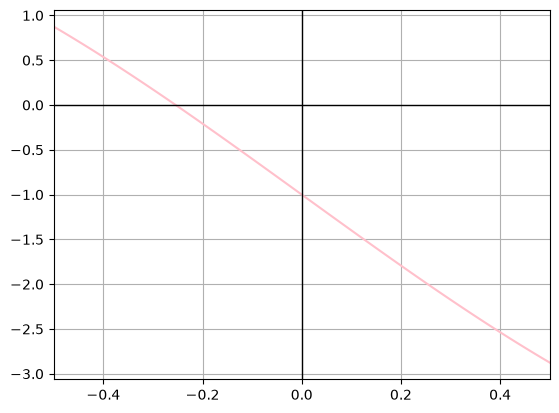

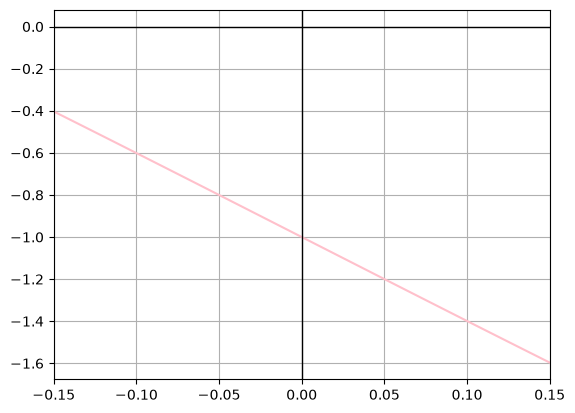

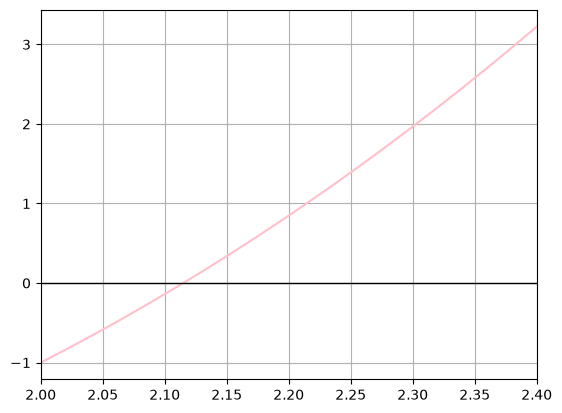

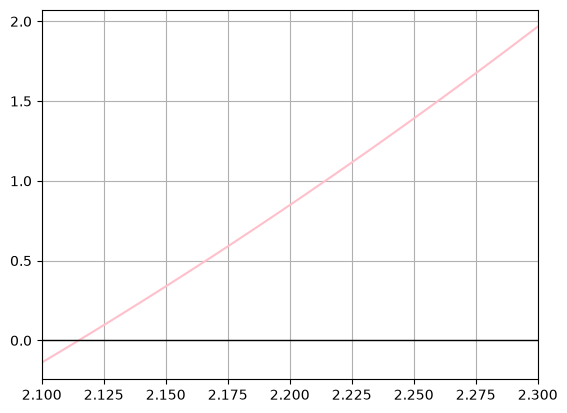

In [54]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return x**3 - 4*x - 1

def plot(a, b):
    intervalo = np.linspace(a, b, 100)
    plt.plot(intervalo, f(intervalo), label = 'f(x)', color = 'pink')
    plt.axhline(0, linestyle = '-', linewidth = 1, color = 'black')
    plt.axvline(0, linestyle = '-', linewidth = 1, color = 'black')
    plt.xlim(a, b)
    plt.grid()
    plt.show()

plot(1, 10)
plot(-10, 20)
plot(-6, 6)
plot(-2.3, 2.3)

# primeiro intervalo (negativo)
plot(-2, -1.6)
plot(-1.95, 1.85)

# segundo intervalo (negativo)
plot(-0.5, 0.5)
plot(-0.15, 0.15)

# terceiro intervalo (positivo)
plot(2, 2.4)
plot(2.10, 2.30)

Os intervalos que contém uma raiz real são: [-1.95, 1.85] [-0.15, 0.15] e [2.10, 2.30]

Por meio da plotagem do gráfico da função, foram identificadas três regiões em que a curva cruza o eixo das abscissas. Para isolar as raízes, foram selecionados intervalos menores ao redor de cada cruzamento, de modo que cada intervalo contenha uma única raiz real.

## 2) Método da Falsa Posição

f(x) = e^-x - x 

In [55]:
import pandas as pd
import numpy as np

def f(x):
    return np.exp(-x) - x 

def posicaoFalsa(a, b, TOL, n):
    historico = []
    x_ant = float('nan')

    for k in range(1, n + 1):
        x = (a * f(b) - b * f(a)) / (f(b) - f(a))
        epsilon = abs((x - x_ant) / (max(x, 1)))
        x_ant = x

        historico.append({
            "k": k, "a": a, "b": b, "e": epsilon, "f(x)": f(x),
            "f(x) x f(a)": f(x) * f(a)
        })

        if (f(x) == 0 or epsilon < TOL):
            break
        
        if (f(x) * f(a) > 0):
            a = x
        else:
            b = x

    df = pd.DataFrame(historico)
    print(df)

posicaoFalsa(0, 1, 1e-6, 100)

   k  a         b             e          f(x)   f(x) x f(a)
0  1  0  1.000000           NaN -7.081395e-02 -7.081395e-02
1  2  0  0.612700  4.051842e-02 -7.888273e-03 -7.888273e-03
2  3  0  0.572181  4.478198e-03 -8.773920e-04 -8.773920e-04
3  4  0  0.567703  4.976616e-04 -9.757273e-05 -9.757273e-05
4  5  0  0.567206  5.533839e-05 -1.085062e-05 -1.085062e-05
5  6  0  0.567150  6.153865e-06 -1.206646e-06 -1.206646e-06
6  7  0  0.567144  6.843412e-07 -1.341853e-07 -1.341853e-07


O erro 6.843412e-07 é menor que 1e-6. Logo, a função converge para a raiz aproximada 0.567144.

## 3) Método do Ponto Fixo

f(x) = cos(x) - x

In [56]:
import numpy as np

def f(x):
    return np.cos(x) - x

def g(x):
    return np.cos(x)

def pontoFixo(a, b, TOL, n):
    historico = []
    x = (a + b) / 2
    x_ant = float('nan')

    for k in range(1, n + 1):
        x = g(x)
        epsilon = abs((x - x_ant) / (max(x, 1)))
        x_ant = x

        historico.append({
            "k": k, "a": a, "b": b, "erro": epsilon, "x": x,
            "f(x)": f(x)
        })

        if (f(x) == 0 or epsilon < TOL):
            break

    df = pd.DataFrame(historico)
    print(df)

pontoFixo(-1, 1, 1e-6, 100)

     k  a  b          erro         x          f(x)
0    1 -1  1           NaN  1.000000 -4.596977e-01
1    2 -1  1  4.596977e-01  0.540302  3.172509e-01
2    3 -1  1  3.172509e-01  0.857553 -2.032634e-01
3    4 -1  1  2.032634e-01  0.654290  1.391906e-01
4    5 -1  1  1.391906e-01  0.793480 -9.211159e-02
5    6 -1  1  9.211159e-02  0.701369  6.259091e-02
6    7 -1  1  6.259091e-02  0.763960 -4.185726e-02
7    8 -1  1  4.185726e-02  0.722102  2.831534e-02
8    9 -1  1  2.831534e-02  0.750418 -1.901372e-02
9   10 -1  1  1.901372e-02  0.731404  1.283331e-02
10  11 -1  1  1.283331e-02  0.744237 -8.632614e-03
11  12 -1  1  8.632614e-03  0.735605  5.820346e-03
12  13 -1  1  5.820346e-03  0.741425 -3.918196e-03
13  14 -1  1  3.918196e-03  0.737507  2.640445e-03
14  15 -1  1  2.640445e-03  0.740147 -1.778131e-03
15  16 -1  1  1.778131e-03  0.738369  1.197998e-03
16  17 -1  1  1.197998e-03  0.739567 -8.068823e-04
17  18 -1  1  8.068823e-04  0.738760  5.435725e-04
18  19 -1  1  5.435725e-04  0.7

O erro 9.767867e-07 é menor que 1e-6. Logo, a função converge na raiz aproximada de 0.739086.

## 4) Método de Newton-Raphson

f(x) = x^3 - 2x - 5

In [57]:
import sympy as sy

def f(x):
    return x**3 - 2 * x  - 5

# descobrindo a derivada
x_sy = sy.Symbol('x')
funcao = x_sy**3 - 2 * x_sy - 5
derivada = sy.diff(funcao, x_sy)
print(derivada)

def g(x):
    return 3*x**2 - 2

def newtonRaphson(a, b, TOL, n):
    historico = []
    x = (a + b) / 2
    x_ant = float('nan')

    for k in range(1, n + 1):
        erro = abs((x - x_ant) / (max(x, 1)))

        historico.append({
            "k": k, "x": x, "f(x)": f(x), "erro": erro
        })

        if (f(x) == 0 or erro < TOL):
            break

        x_ant = x
        x = x - (f(x) / g(x))

    df = pd.DataFrame(historico)
    print(df)

newtonRaphson(-5, 6, 1e-6, 100)


3*x**2 - 2
     k          x          f(x)          erro
0    1   0.500000 -5.875000e+00           NaN
1    2  -4.200000 -7.068800e+01  4.700000e+00
2    3  -2.811783 -2.160674e+01  1.388217e+00
3    4  -1.816923 -7.364198e+00  9.948600e-01
4    5  -0.885174 -3.923215e+00  9.317489e-01
5    6  10.304820  1.068652e+03  1.085899e+00
6    7   6.929076  3.138214e+02  4.871852e-01
7    8   4.719632  9.069017e+01  4.681392e-01
8    9   3.320627  2.497385e+01  4.213075e-01
9   10   2.517084  5.913359e+00  3.192354e-01
10  11   2.169386  8.708686e-01  1.602751e-01
11  12   2.097524  3.323753e-02  3.426016e-02
12  13   2.094556  5.540334e-05  1.416982e-03
13  14   2.094551  1.548264e-10  2.369858e-06
14  15   2.094551 -8.881784e-16  6.622693e-12


o erro 6.622693e-12 é menor que 1e-6. Logo, a função converge na raiz aproximada 2.094551.

# 5) Método da Secante

f(x) = x^2 - 3

In [58]:
def f(x):
    return x**2 - 3

# calculando a primeira derivada
x = sy.Symbol('x')
funcao = x**2 - 3
fx_ = sy.diff(funcao, x)
print(fx_)

# calculando a segunda derivada
fx__ = sy.diff(fx_, x)
print(fx__)

def f_(x):
    return 2 * x

def f__(x):
    return 2

def secante(a, b, TOL, n):
    historico = []
    x_ = a
    x__ = b

    for k in range(1, n + 1):
        x = x_ - f(x_) * ((x_ - x__) / (f(x_) - f(x__)))
        erro = abs((x - x_) / (max(x, 1)))

        historico.append({
            "k": k, "x": x, "f(x)": f(x), "erro": erro
        })

        if (f(x) == 0 or erro < TOL):
            break

        x_ = x__
        x__ = x

    df = pd.DataFrame(historico)
    print(df)

secante(-3, 2, 1e-6, 100)


2*x
2
   k         x          f(x)          erro
0  1  3.000000  6.000000e+00  2.000000e+00
1  2  1.800000  2.400000e-01  1.111111e-01
2  3  1.750000  6.250000e-02  7.142857e-01
3  4  1.732394  1.190240e-03  3.902439e-02
4  5  1.732053  6.134210e-06  1.036194e-02
5  6  1.732051  6.083103e-10  1.983536e-04
6  7  1.732051  4.440892e-16  1.022368e-06
7  8  1.732051 -4.440892e-16  1.013851e-10


O erro 9.489651e-07 é menor que 1e-6. Logo, a função converge na raiz aproximada 1.732051.